In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import h5py
from scipy.stats import ttest_ind, mannwhitneyu, pearsonr, spearmanr
import os
# ...existing code...
from sklearn.metrics import (
    roc_auc_score,
    roc_curve,
    precision_recall_curve,
    average_precision_score,
)
from pathlib import Path

In [8]:
data_path = "/home/jake/Documents/AI_Clinician/choc_data/combined_data/hourly_all_patients/" \
"split_0/training_set/train_dynamic_deephit_dataset.h5"

with h5py.File(data_path, "r") as f:
    mortality = f["event"][:]
    # print other keys in the file to check if there are any other relevant data
    print("Keys in the data file:", list(f.keys()))


Keys in the predictions file: ['carry_forward_ind', 'event', 'feature_dim', 'feature_names', 'index_ptr', 'physiological_feature_ind', 'physiological_feature_type', 'response_zero_ind', 'stay_ids', 'time_to_event', 'time_to_event_raw', 'trajectories']


array([0, 0, 0, ..., 0, 0, 0], dtype=int32)

In [19]:
data_path = "/home/jake/Documents/AI_Clinician/models/dynamic_deephit_results/choc/five_splits/split_0/sepsis/intake-vis/final_model"

# get folder name inside datapath
final_model_folder = os.listdir(data_path)[0]
data_path = os.path.join(data_path, final_model_folder)

predictions_file = "train_set_predictions.h5" 
health_score_key = "health_score"  # Adjust this key if your health scores are stored under a different name

predictions_path = os.path.join(data_path, predictions_file)
# Load predictions and health scores
with h5py.File(predictions_path, "r") as f:
    health_scores = f[health_score_key][:]

    mortality = f['event'][:]  # Assuming mortality labels are stored under the key 'event'
    # print other keys in the file to check if there are any other relevant data

    index_ptr = f['index_ptr'][:]  # Assuming index pointers are stored under the key 'index_ptr'

    stay_ids = f['stay_ids'][:]  # Assuming stay IDs are stored under the key 'stay_ids'
    print("Keys in the predictions file:", list(f.keys()))


Keys in the predictions file: ['carry_forward_ind', 'compressed_latents', 'entropy', 'event', 'feature_dim', 'feature_names', 'health_score', 'index_ptr', 'model_outputs', 'physiological_feature_ind', 'physiological_feature_type', 'predictions', 'response_zero_ind', 'stay_ids']


In [17]:
# load the sepsis cohort
sepsis_cohort_path = "/home/jake/Documents/AI_Clinician/choc_data/cohorts/sepsis/stay_ids.csv"
sepsis_cohort = pd.read_csv(sepsis_cohort_path)
sepsis_cohort

,stay_id
0,1163732912
1,1163738773
2,1163740044
3,1163744439
4,1163745160
...,...
5178,1189395190
5179,1189395314
5180,1189418957
5181,1189420203


In [ ]:
def filter_by_stay_ids(health_scores, mortality, index_ptr, stay_ids, stay_ids_to_keep):
           
        print(f"Original number of stays: {len(stay_ids)}")
        
        # Create boolean mask for stays to keep
        mask = np.isin(stay_ids, list(stay_ids_to_keep))
        indices_to_keep = np.where(mask)[0]
        
        print(f"Number of stays after filtering by stay ids: {len(indices_to_keep)}")

        traj_mask = np.zeros(health_scores.shape[0], dtype=bool)
        print(f"Original number of timesteps: {traj_mask.shape[0]}")

        for idx in indices_to_keep:
            start_idx = index_ptr[idx]
            end_idx = index_ptr[idx + 1]
            traj_mask[start_idx:end_idx] = True

        # Apply masks to all arrays at once
        stay_ids = stay_ids [mask]
        mortality = mortality[mask]
        health_scores = health_scores[traj_mask]

        print(f"Number of timesteps after filtering: {health_scores.shape[0]}")

        # Rebuild index_ptr
        new_index_ptr = np.zeros(len(indices_to_keep) + 1, dtype=np.int32)
        for i, idx in enumerate(indices_to_keep):
            start_idx = index_ptr[idx]
            end_idx = index_ptr[idx + 1]
            new_index_ptr[i + 1] = new_index_ptr[i] + (end_idx - start_idx)
        
        index_ptr = new_index_ptr
        # logger.info(f"Number of timesteps after filtering to cohort {cohort}: {dataset['trajectories'].shape[0]}")
 
        return health_scores, mortality, index_ptr, stay_ids

In [24]:
health_scores, mortality, index_ptr, stay_ids = filter_by_stay_ids(
    health_scores, 
    mortality, 
    index_ptr, 
    stay_ids, 
    sepsis_cohort['stay_id'].values)

Original number of stays: 6733
Number of stays after filtering by stay ids: 1488
Original number of timesteps: 2488216
Number of stay_ids after filtering: 1488
Number of timesteps after filtering: 715424


In [27]:
# expand mortality to match the length of health_scores
expanded_mortality = np.zeros_like(health_scores, dtype=int)
for i in range(len(index_ptr) - 1):
    start_idx = index_ptr[i]
    end_idx = index_ptr[i + 1]
    expanded_mortality[start_idx:end_idx] = mortality[i]

In [29]:
survival_health_scores = health_scores[expanded_mortality == 0]
death_health_scores = health_scores[expanded_mortality == 1]

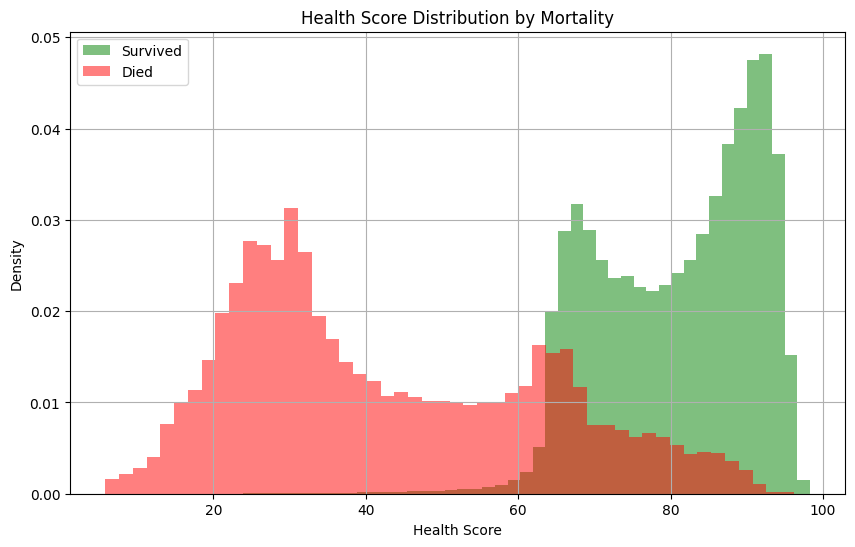

In [31]:
plt.figure(figsize=(10,6))
plt.hist(survival_health_scores, bins=50, alpha=0.5, label='Survived', color='g', density=True)
plt.hist(death_health_scores, bins=50, alpha=0.5, label='Died', color='r', density=True)
plt.xlabel('Health Score')
plt.ylabel('Density')
plt.title('Health Score Distribution by Mortality')
plt.legend()
plt.grid(True)
plt.show()



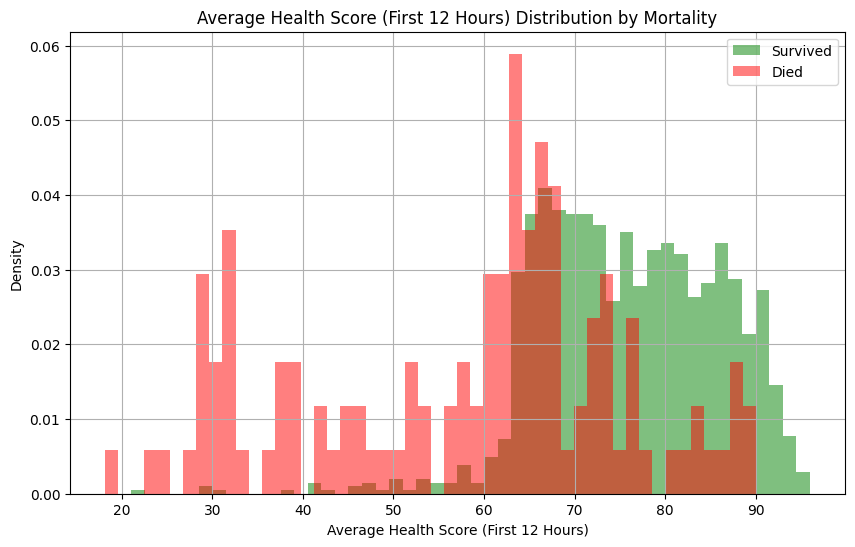

In [44]:
# for each trajectory, average the health score over the first 12 hours
health_score_12h = []
for i in range(len(index_ptr) - 1):
    start_idx = index_ptr[i]
    end_idx = index_ptr[i + 1]
    traj_health_scores = health_scores[start_idx:end_idx]
    avg_health_score_12h = traj_health_scores[:12].mean()  # Average over first 12 hours
    health_score_12h.append(avg_health_score_12h)

# separate by mortality
survival_health_score_12h = [health_score_12h[i] for i in range(len(mortality)) if mortality[i] == 0]
death_health_score_12h = [health_score_12h[i] for i in range(len(mortality)) if mortality[i] == 1]

plt.figure(figsize=(10,6))
plt.hist(survival_health_score_12h, bins=50, alpha=0.5, label='Survived', color='g', density=True)
plt.hist(death_health_score_12h, bins=50, alpha=0.5, label='Died', color='r', density=True)
plt.xlabel('Average Health Score (First 12 Hours)')
plt.ylabel('Density')
plt.title('Average Health Score (First 12 Hours) Distribution by Mortality')
plt.legend()
plt.grid(True)

In [32]:
# compute hourly health score differences for each stay, making final hour 0
health_score_diffs = []
for i in range(len(index_ptr) - 1):
    start_idx = index_ptr[i]
    end_idx = index_ptr[i + 1]
    scores = health_scores[start_idx:end_idx]
    diffs = np.diff(scores, prepend=scores[0])  # Prepend first score to keep same length
    health_score_diffs.append(diffs)

In [33]:
survival_health_score_diffs = np.concatenate([health_score_diffs[i] for i in range(len(index_ptr) - 1) if expanded_mortality[i] == 0])
death_health_score_diffs = np.concatenate([health_score_diffs[i] for i in range(len(index_ptr) - 1) if expanded_mortality[i] == 1])

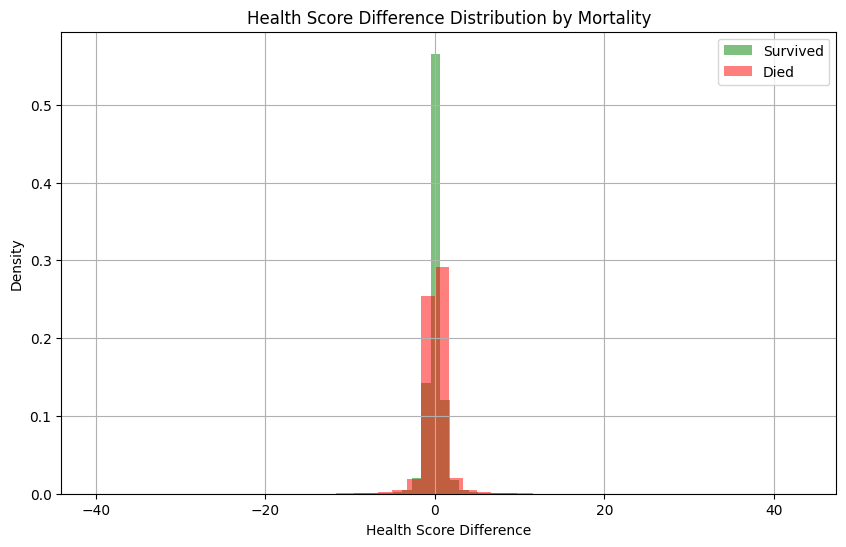

In [34]:
plt.figure(figsize=(10,6))
plt.hist(survival_health_score_diffs, bins=50, alpha=0.5, label='Survived', color='g', density=True)
plt.hist(death_health_score_diffs, bins=50, alpha=0.5, label='Died', color='r', density=True)
plt.xlabel('Health Score Difference')
plt.ylabel('Density')
plt.title('Health Score Difference Distribution by Mortality')
plt.legend()
plt.grid(True)
plt.show()


In [35]:
# for each stay id, compute the health score difference between the first and last hour, and compare between survivors and non-survivors
final_health_score_diffs = []
for i in range(len(index_ptr) - 1):
    start_idx = index_ptr[i]
    end_idx = index_ptr[i + 1]
    score_diff = health_scores[end_idx - 1] - health_scores[start_idx]  # Last hour - first hour
    final_health_score_diffs.append(score_diff)

survival_final_diffs = [final_health_score_diffs[i] for i in range(len(index_ptr) - 1) if expanded_mortality[i] == 0]
death_final_diffs = [final_health_score_diffs[i] for i in range(len(index_ptr) - 1) if expanded_mortality[i] == 1]

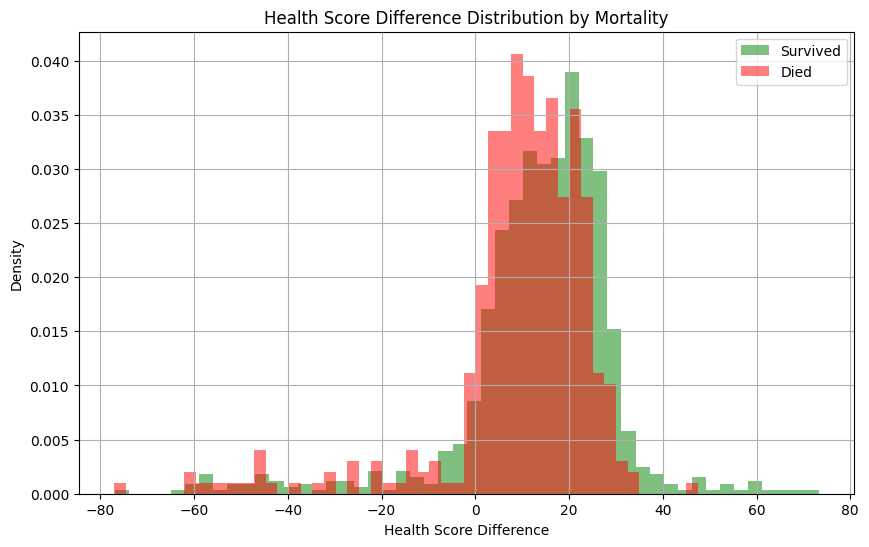

In [36]:
plt.figure(figsize=(10,6))
plt.hist(survival_final_diffs, bins=50, alpha=0.5, label='Survived', color='g', density=True)
plt.hist(death_final_diffs, bins=50, alpha=0.5, label='Died', color='r', density=True)
plt.xlabel('Health Score Difference')
plt.ylabel('Density')
plt.title('Health Score Difference Distribution by Mortality')
plt.legend()
plt.grid(True)
plt.show()

## test some smoothing

In [41]:
import pandas as pd
import numpy as np

def smooth_by_trajectory(values, index_ptr, window=6):
    """
    Apply rolling mean smoothing per trajectory.
    
    values:    (N,) array of per-timestep values
    index_ptr: (num_trajectories+1,) array of trajectory boundaries
    window:    smoothing window in hours
    """
    smoothed = np.zeros_like(values, dtype=np.float32)
    
    for start, end in zip(index_ptr[:-1], index_ptr[1:]):
        traj = values[start:end]
        smoothed[start:end] = (
            pd.Series(traj)
            .rolling(window, center=True, min_periods=1)
            .mean()
            .values
        )
    return smoothed

# Apply smoothing
health_score_smoothed = smooth_by_trajectory(health_scores, index_ptr, window=6)

# Recompute diffs from smoothed scores
health_score_diffs_smoothed = np.zeros_like(health_score_smoothed)
for start, end in zip(index_ptr[:-1], index_ptr[1:]):
    traj = health_score_smoothed[start:end]
    health_score_diffs_smoothed[start:end] = np.diff(traj, prepend=traj[0])

# Median-centered reward
median_health = np.median(health_score_smoothed)
reward_smoothed = health_score_smoothed - median_health

print(f"Median health score: {median_health:.2f}")
print(f"Reward range: [{reward_smoothed.min():.2f}, {reward_smoothed.max():.2f}]")

# Quick separation check
survivor_returns    = [reward_smoothed[s:e].sum() for s, e, m in 
                       zip(index_ptr[:-1], index_ptr[1:], mortality) if m == 0]
nonsurvivor_returns = [reward_smoothed[s:e].sum() for s, e, m in 
                       zip(index_ptr[:-1], index_ptr[1:], mortality) if m == 1]

print(f"Survivor return:     {np.mean(survivor_returns):.1f} ± {np.std(survivor_returns):.1f}")
print(f"Non-survivor return: {np.mean(nonsurvivor_returns):.1f} ± {np.std(nonsurvivor_returns):.1f}")
print(f"Separation:          {np.mean(survivor_returns) - np.mean(nonsurvivor_returns):.1f}")

Median health score: 81.02
Reward range: [-75.19, 17.13]
Survivor return:     -65.3 ± 3634.2
Non-survivor return: -18780.8 ± 17881.2
Separation:          18715.6


In [42]:
# Normalise by trajectory length to remove length effect
survivor_returns_norm    = [reward_smoothed[s:e].mean() for s, e, m in 
                            zip(index_ptr[:-1], index_ptr[1:], mortality) if m == 0]
nonsurvivor_returns_norm = [reward_smoothed[s:e].mean() for s, e, m in 
                            zip(index_ptr[:-1], index_ptr[1:], mortality) if m == 1]

print(f"Survivor mean reward/step:     {np.mean(survivor_returns_norm):.2f} ± {np.std(survivor_returns_norm):.2f}")
print(f"Non-survivor mean reward/step: {np.mean(nonsurvivor_returns_norm):.2f} ± {np.std(nonsurvivor_returns_norm):.2f}")

Survivor mean reward/step:     2.81 ± 6.89
Non-survivor mean reward/step: -35.04 ± 16.17


In [43]:
median_unsmoothed = np.median(health_scores)
reward_unsmoothed = health_scores - median_unsmoothed

median_smoothed   = np.median(health_score_smoothed)
reward_smoothed   = health_score_smoothed - median_smoothed

for name, reward in [('unsmoothed level - median', reward_unsmoothed), 
                     ('smoothed level - median',   reward_smoothed)]:
    
    survivor_per_step    = [reward[s:e].mean() for s, e, m in 
                            zip(index_ptr[:-1], index_ptr[1:], mortality) if m == 0]
    nonsurvivor_per_step = [reward[s:e].mean() for s, e, m in 
                            zip(index_ptr[:-1], index_ptr[1:], mortality) if m == 1]
    
    # Per-step separation
    sep = np.mean(survivor_per_step) - np.mean(nonsurvivor_per_step)
    
    # Per-step noise (mean std within trajectories)
    survivor_noise    = np.mean([reward[s:e].std() for s, e, m in 
                                 zip(index_ptr[:-1], index_ptr[1:], mortality) if m == 0])
    nonsurvivor_noise = np.mean([reward[s:e].std() for s, e, m in 
                                 zip(index_ptr[:-1], index_ptr[1:], mortality) if m == 1])

    print(f"\n{name}")
    print(f"  Survivor mean/step:     {np.mean(survivor_per_step):.2f} ± {np.std(survivor_per_step):.2f}")
    print(f"  Non-survivor mean/step: {np.mean(nonsurvivor_per_step):.2f} ± {np.std(nonsurvivor_per_step):.2f}")
    print(f"  Separation:             {sep:.2f}")
    print(f"  Within-traj noise (survivor):     {survivor_noise:.2f}")
    print(f"  Within-traj noise (non-survivor): {nonsurvivor_noise:.2f}")


unsmoothed level - median
  Survivor mean/step:     2.80 ± 6.90
  Non-survivor mean/step: -35.14 ± 16.17
  Separation:             37.94
  Within-traj noise (survivor):     6.04
  Within-traj noise (non-survivor): 12.62

smoothed level - median
  Survivor mean/step:     2.81 ± 6.89
  Non-survivor mean/step: -35.04 ± 16.17
  Separation:             37.85
  Within-traj noise (survivor):     6.01
  Within-traj noise (non-survivor): 12.41
